# 00_01 Random Variables: PMF, PDF, CDF and Quantiles

**Learning objectives**
- Say what a **random variable** is, and tell **discrete** from **continuous** ones.
- Use the **PMF**, **PDF**, **CDF**, **survival function** and **quantile (PPF)** and move between them.
- Compute probabilities of ranges from the CDF, by hand, in code and by simulation.

**Prerequisites:** none (this is the first lesson of the foundations module).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A **random experiment** has uncertain outcomes (roll two dice, time a customer's wait). The set of all outcomes is the **sample space**.
- An **event** is a set of outcomes; its probability is between 0 and 1, and probabilities of all outcomes add up to 1.
- With equally likely outcomes, $P(A)=\dfrac{\text{number of outcomes in }A}{\text{total number of outcomes}}$.
- **Integral = area under a curve**; the derivative undoes the integral.

## 3. Intuition and story

A **random variable** $X$ is a number produced by a random experiment: the sum of two dice, the minutes a customer waits, the number of orders today. It turns outcomes into numbers so that we can compute with them.

- **Discrete** random variable: takes separate values (0, 1, 2, ...). We describe it by a **PMF** (probability mass function), $p(x)=P(X=x)$.
- **Continuous** random variable: any value in an interval (a waiting time). A single value has probability 0, so we describe it by a **PDF** (probability density function) $f(x)$, and probabilities are **areas**: $P(a\le X\le b)=\int_a^bf(x)\,dx$.

Both have a **CDF** $F(x)=P(X\le x)$, the running total of probability up to $x$. The CDF is the universal description: it exists for every random variable and goes from 0 to 1.

## 4. Formal definition

| Object | Discrete | Continuous |
|---|---|---|
| Description | PMF $p(x)=P(X=x)$, $\sum_xp(x)=1$ | PDF $f(x)\ge0$, $\int f=1$ |
| CDF $F(x)=P(X\le x)$ | $\sum_{t\le x}p(t)$ (a staircase) | $\int_{-\infty}^xf(t)dt$ (a smooth curve) |
| $P(a<X\le b)$ | $F(b)-F(a)$ | $F(b)-F(a)=\int_a^bf$ |
| Survival $S(x)=P(X>x)$ | $1-F(x)$ | $1-F(x)$ |
| Quantile (PPF) $F^{-1}(p)$ | smallest $x$ with $F(x)\ge p$ | the $x$ with $F(x)=p$ |

Properties of every CDF: it never decreases, $F(-\infty)=0$, $F(\infty)=1$, and it is right-continuous. For continuous variables $f(x)=F'(x)$.

## 5. Derivations

**PMF of the sum of two dice by counting.** The 36 outcomes $(d_1,d_2)$ are equally likely. The sum $s$ occurs in $\min(s-1,\,13-s)$ outcomes for $s=2,\dots,12$, so $p(s)=\dfrac{\min(s-1,13-s)}{36}$: $p(2)=\frac1{36}$, $p(7)=\frac6{36}$, $p(12)=\frac1{36}$.

**CDF from PDF (Exponential).** For $f(x)=\lambda e^{-\lambda x}$, $x\ge0$: $F(x)=\int_0^x\lambda e^{-\lambda t}dt=1-e^{-\lambda x}$, and $S(x)=e^{-\lambda x}$.

**Quantile function (inverse CDF).** Solve $F(x_p)=p$: $1-e^{-\lambda x_p}=p\Rightarrow x_p=-\dfrac{\ln(1-p)}{\lambda}$. The median is $\ln2/\lambda$.

**Range probabilities.** $P(a<X\le b)=P(X\le b)-P(X\le a)=F(b)-F(a)$, because the event $\{X\le b\}$ is the disjoint union of $\{X\le a\}$ and $\{a<X\le b\}$.

**In plain words.** The CDF is the cumulative bar of probability. Differences of the CDF give probabilities of ranges, the PDF is its slope, and the quantile function reads the CDF backwards ("what value leaves 90 % of the probability below it?").

## 6. Properties and relationships

- Discrete CDFs **jump** by the PMF value at each possible value; continuous CDFs are smooth.
- For continuous $X$, $P(X=x)=0$, so $P(X\le a)=P(X<a)$. For discrete $X$ the difference matters.
- The **quantile function** also generates random numbers: if $U\sim\text{Uniform}(0,1)$ then $F^{-1}(U)$ has CDF $F$ (inverse transform sampling, used in Module 12).
- A **mixed** random variable (a wait that is 0 for half the customers and continuous otherwise) has both jumps and a smooth part.

## 7. 2D visuals

### 7.1 A discrete variable: the sum of two dice
Bars are the PMF; the staircase is the CDF.

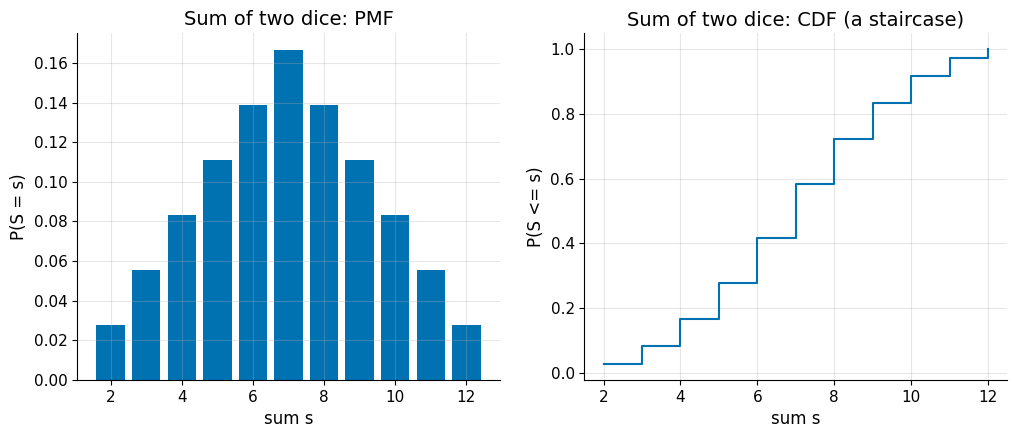

In [2]:
sums = np.arange(2, 13)
pmf_values = np.array([min(s - 1, 13 - s) / 36 for s in sums])      # counting formula from section 5
cdf_values = np.cumsum(pmf_values)

fig, (ax_pmf, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_pmf.bar(sums, pmf_values, color=MAIN)
ax_pmf.set_title("Sum of two dice: PMF")
ax_pmf.set_xlabel("sum s")
ax_pmf.set_ylabel("P(S = s)")
ax_cdf.step(sums, cdf_values, where="post", color=MAIN)
ax_cdf.set_title("Sum of two dice: CDF (a staircase)")
ax_cdf.set_xlabel("sum s")
ax_cdf.set_ylabel("P(S <= s)")
plt.show()
assert np.isclose(pmf_values.sum(), 1)

### 7.2 A continuous variable: a waiting time
The PDF shows how probability is spread; the CDF accumulates it; the survival function is what remains.

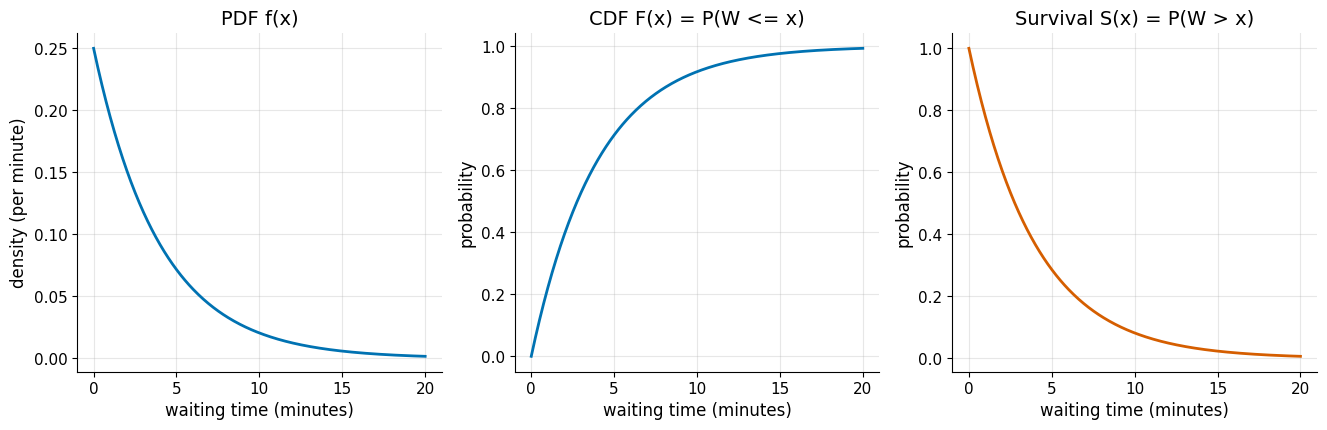

In [3]:
lam = 0.25                                  # rate: 0.25 customers per minute, mean wait 4 minutes
wait = stats.expon(scale=1 / lam)
x_axis = np.linspace(0, 20, 400)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].plot(x_axis, wait.pdf(x_axis), color=MAIN, linewidth=2)
axes[0].set_title("PDF f(x)")
axes[0].set_xlabel("waiting time (minutes)")
axes[0].set_ylabel("density (per minute)")
axes[1].plot(x_axis, wait.cdf(x_axis), color=MAIN, linewidth=2)
axes[1].set_title("CDF F(x) = P(W <= x)")
axes[1].set_xlabel("waiting time (minutes)")
axes[1].set_ylabel("probability")
axes[2].plot(x_axis, wait.sf(x_axis), color=HIGHLIGHT, linewidth=2)
axes[2].set_title("Survival S(x) = P(W > x)")
axes[2].set_xlabel("waiting time (minutes)")
axes[2].set_ylabel("probability")
plt.show()

### 7.3 Quantiles read the CDF backwards
Start at a probability on the vertical axis, move across to the CDF, and read the value below.

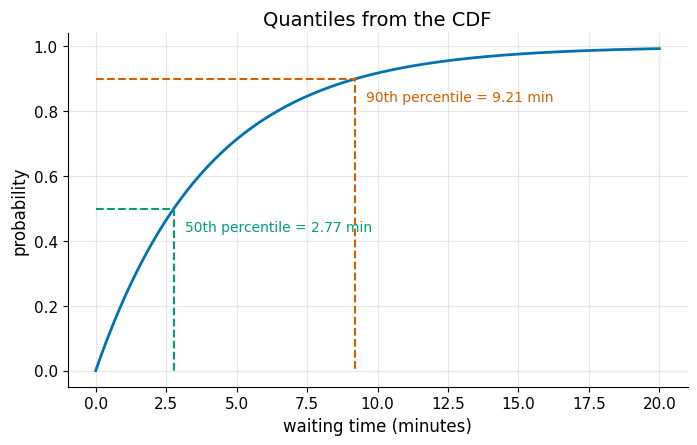

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(x_axis, wait.cdf(x_axis), color=MAIN, linewidth=2)
for p, color in [(0.5, COLORS[2]), (0.9, HIGHLIGHT)]:
    value = wait.ppf(p)
    ax.plot([0, value, value], [p, p, 0], color=color, linestyle="--")
    ax.annotate(f"{int(p * 100)}th percentile = {value:.2f} min", (value, p), textcoords="offset points", xytext=(8, -16), color=color)
ax.set_title("Quantiles from the CDF")
ax.set_xlabel("waiting time (minutes)")
ax.set_ylabel("probability")
plt.show()

## 8. 3D visuals

### 8.1 Static: the 36 outcomes of two dice as 3D bars
Each bar is one equally likely outcome (probability 1/36); the sum is the diagonal.

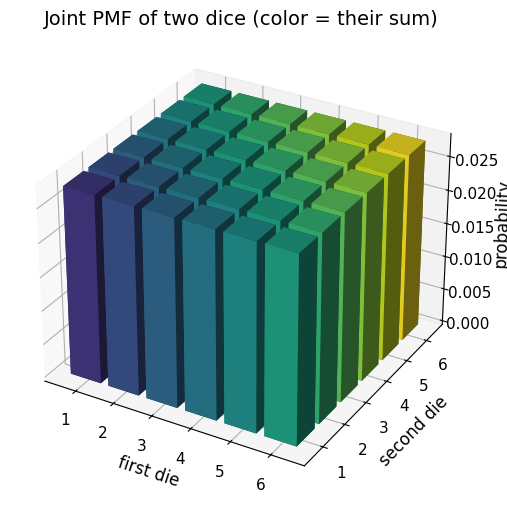

In [5]:
die_values = np.arange(1, 7)
D1, D2 = np.meshgrid(die_values, die_values)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
colors = plt.cm.viridis((D1 + D2).ravel() / 12)
ax.bar3d(D1.ravel() - 0.4, D2.ravel() - 0.4, np.zeros(36), 0.8, 0.8, np.full(36, 1 / 36), color=colors)
ax.set_title("Joint PMF of two dice (color = their sum)")
ax.set_xlabel("first die")
ax.set_ylabel("second die")
ax.set_zlabel("probability")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: the Exponential PDF over (x, lambda)

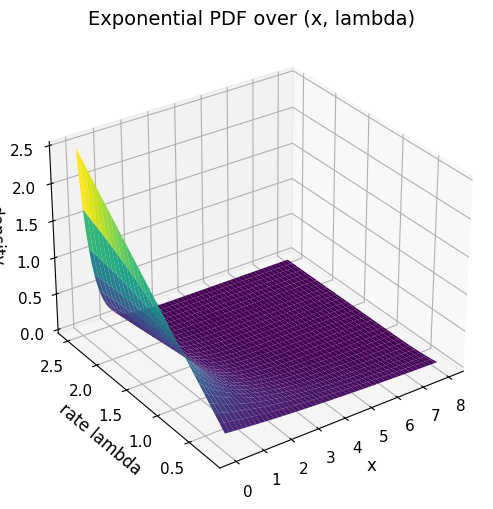

In [6]:
x_values = np.linspace(0, 8, 100)
lam_values = np.linspace(0.2, 2.5, 30)
X, L = np.meshgrid(x_values, lam_values)
Z = L * np.exp(-L * X)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, L, Z, cmap="viridis", edgecolor="none")
ax.set_title("Exponential PDF over (x, lambda)")
ax.set_xlabel("x")
ax.set_ylabel("rate lambda")
ax.set_zlabel("density")
ax.view_init(elev=30, azim=-125)
plt.show()

### 8.3 Interactive Plotly version

In [7]:
fig = go.Figure(go.Surface(x=x_values, y=lam_values, z=Z, colorscale="Viridis"))
fig.update_layout(title="Exponential PDF over (x, lambda)", width=750, height=550,
                  scene=dict(xaxis_title="x", yaxis_title="rate lambda", zaxis_title="density"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram of simulated sums against the PMF

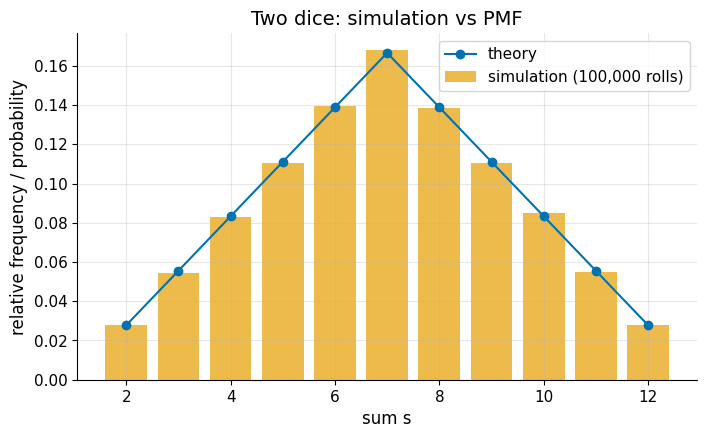

In [8]:
rolls = rng.integers(1, 7, size=(100_000, 2)).sum(axis=1)
relative_freq = np.bincount(rolls, minlength=13)[2:] / len(rolls)
fig, ax = plt.subplots()
ax.bar(sums, relative_freq, color=SIM, alpha=0.7, label="simulation (100,000 rolls)")
ax.plot(sums, pmf_values, "o-", color=MAIN, label="theory")
ax.set_title("Two dice: simulation vs PMF")
ax.set_xlabel("sum s")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()

### 9.2 Running mean of the waiting times

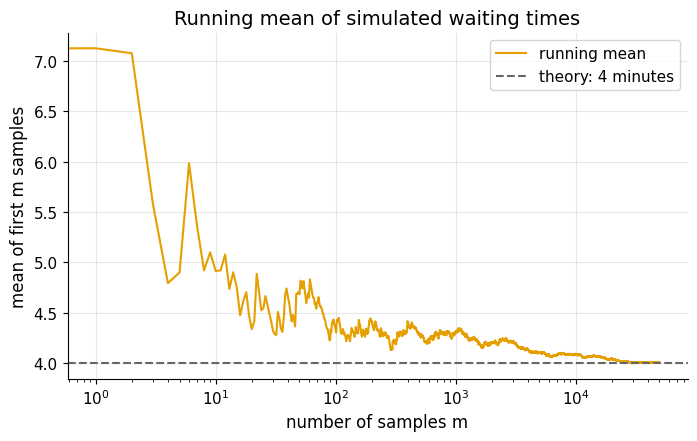

In [9]:
waits = rng.exponential(scale=4, size=50_000)
running_mean = np.cumsum(waits) / np.arange(1, len(waits) + 1)
fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(4, color=NEUTRAL, linestyle="--", label="theory: 4 minutes")
ax.set_xscale("log")
ax.set_title("Running mean of simulated waiting times")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

Every distribution object has the same methods, which map to this lesson's vocabulary.

In [10]:
w = stats.expon(scale=4)
print("pdf(2)   density f(2)        :", round(w.pdf(2), 4))
print("cdf(6)   F(6) = P(W <= 6)    :", round(w.cdf(6), 4))
print("sf(6)    S(6) = P(W > 6)     :", round(w.sf(6), 4))
print("ppf(0.9) 90th percentile     :", round(w.ppf(0.9), 4))
print("rvs(3)   random draws        :", w.rvs(size=3, random_state=1).round(2))
d = stats.randint(1, 7)                                     # one fair die (discrete: pmf instead of pdf)
print("die pmf(3), cdf(3), ppf(0.5) :", d.pmf(3), d.cdf(3), d.ppf(0.5))

pdf(2)   density f(2)        : 0.1516
cdf(6)   F(6) = P(W <= 6)    : 0.7769
sf(6)    S(6) = P(W > 6)     : 0.2231
ppf(0.9) 90th percentile     : 9.2103
rvs(3)   random draws        : [2.16 5.1  0.  ]
die pmf(3), cdf(3), ppf(0.5) : 0.16666666666666666 0.5 3.0


## 11. Real-world worked example: waiting times at a bank

**Scenario (illustrative numbers).** Customers wait on average **4 minutes** before being served; waiting times follow an Exponential distribution (rate $\lambda=0.25$ per minute).

**Questions**
1. What is the probability that a customer waits **more than 6 minutes**?
2. What is the probability that a wait is **between 2 and 5 minutes**?
3. What is the **median** wait, and the wait exceeded by only **10 %** of customers (the 90th percentile)?

### 11.1 By hand
**Q1.** $S(6)=e^{-0.25\times6}=e^{-1.5}=0.2231$.

**Q2.** $P(2\le W\le5)=F(5)-F(2)=\big(1-e^{-1.25}\big)-\big(1-e^{-0.5}\big)=e^{-0.5}-e^{-1.25}=0.6065-0.2865=0.3200$.

**Q3.** $x_p=-\ln(1-p)/\lambda=4\times(-\ln(1-p))$: median $=4\ln2=2.773$ min; 90th percentile $=4\ln10=9.210$ min.

In [11]:
import math

rate = 0.25
p_over_6_hand = math.exp(-rate * 6)
p_2_to_5_hand = math.exp(-rate * 2) - math.exp(-rate * 5)
median_hand = -math.log(1 - 0.5) / rate
p90_hand = -math.log(1 - 0.9) / rate
print(f"P(W > 6) = {p_over_6_hand:.4f}, P(2 <= W <= 5) = {p_2_to_5_hand:.4f}, median = {median_hand:.3f}, 90th percentile = {p90_hand:.3f}")

P(W > 6) = 0.2231, P(2 <= W <= 5) = 0.3200, median = 2.773, 90th percentile = 9.210


### 11.2 In code with `scipy`, and the asserts

In [12]:
bank = stats.expon(scale=1 / rate)
assert np.isclose(p_over_6_hand, bank.sf(6))
assert np.isclose(p_2_to_5_hand, bank.cdf(5) - bank.cdf(2))
assert np.isclose(median_hand, bank.ppf(0.5))
assert np.isclose(p90_hand, bank.ppf(0.9))
print(f"P(W > 6) = {bank.sf(6):.4f}; P(2 <= W <= 5) = {bank.cdf(5) - bank.cdf(2):.4f}; median {bank.median():.3f}; p90 {bank.ppf(0.9):.3f}")

P(W > 6) = 0.2231; P(2 <= W <= 5) = 0.3200; median 2.773; p90 9.210


### 11.3 Verify by simulation

In [13]:
simulated = rng.exponential(1 / rate, size=500_000)
print(f"P(W > 6):        exact {bank.sf(6):.4f}  simulated {np.mean(simulated > 6):.4f}")
print(f"P(2 <= W <= 5):  exact {bank.cdf(5) - bank.cdf(2):.4f}  simulated {np.mean((simulated >= 2) & (simulated <= 5)):.4f}")
print(f"median / p90:    exact {bank.ppf(0.5):.3f} / {bank.ppf(0.9):.3f}  simulated {np.median(simulated):.3f} / {np.percentile(simulated, 90):.3f}")
assert abs(np.mean(simulated > 6) - bank.sf(6)) < 0.003
assert abs(np.percentile(simulated, 90) - bank.ppf(0.9)) < 0.1

P(W > 6):        exact 0.2231  simulated 0.2227
P(2 <= W <= 5):  exact 0.3200  simulated 0.3200
median / p90:    exact 2.773 / 9.210  simulated 2.767 / 9.196


### 11.4 Plots with the regions shaded

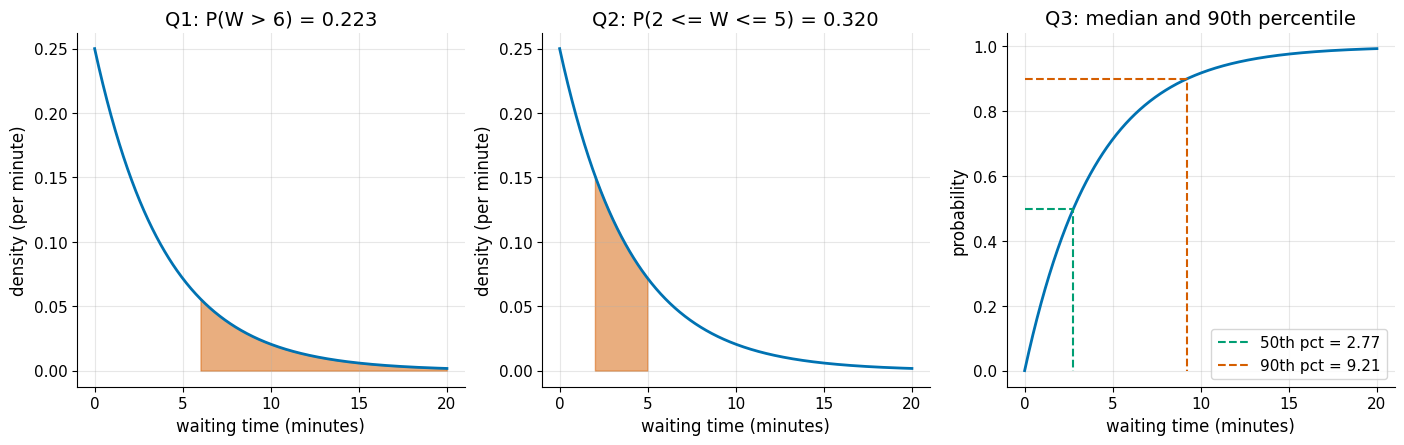

In [14]:
x_axis = np.linspace(0, 20, 600)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
tail = x_axis > 6
axes[0].plot(x_axis, bank.pdf(x_axis), color=MAIN, linewidth=2)
axes[0].fill_between(x_axis[tail], bank.pdf(x_axis[tail]), color=HIGHLIGHT, alpha=0.5)
axes[0].set_title(f"Q1: P(W > 6) = {bank.sf(6):.3f}")
band = (x_axis >= 2) & (x_axis <= 5)
axes[1].plot(x_axis, bank.pdf(x_axis), color=MAIN, linewidth=2)
axes[1].fill_between(x_axis[band], bank.pdf(x_axis[band]), color=HIGHLIGHT, alpha=0.5)
axes[1].set_title(f"Q2: P(2 <= W <= 5) = {bank.cdf(5) - bank.cdf(2):.3f}")
axes[2].plot(x_axis, bank.cdf(x_axis), color=MAIN, linewidth=2)
for p, color in [(0.5, COLORS[2]), (0.9, HIGHLIGHT)]:
    axes[2].plot([0, bank.ppf(p), bank.ppf(p)], [p, p, 0], "--", color=color, label=f"{int(p * 100)}th pct = {bank.ppf(p):.2f}")
axes[2].set_title("Q3: median and 90th percentile")
for ax in axes:
    ax.set_xlabel("waiting time (minutes)")
axes[0].set_ylabel("density (per minute)")
axes[1].set_ylabel("density (per minute)")
axes[2].set_ylabel("probability")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- About **22 %** of customers wait more than 6 minutes, and **32 %** wait between 2 and 5 minutes.
- The **median wait is only 2.8 minutes** although the average is 4: a few long waits pull the mean up.
- **Decision:** a service promise of "served within 9 minutes" would be met for 90 % of customers; promising 4 minutes (the average) would fail for 37 % of them.

### 11.6 Extra example: the sum of two dice (a discrete variable)
What is $P(S\ge10)$ and $P(S=7)$? Count the favourable outcomes among the 36.

In [15]:
favourable_10 = sum(1 for d1 in range(1, 7) for d2 in range(1, 7) if d1 + d2 >= 10)
favourable_7 = sum(1 for d1 in range(1, 7) for d2 in range(1, 7) if d1 + d2 == 7)
p10_hand, p7_hand = favourable_10 / 36, favourable_7 / 36
assert np.isclose(p10_hand, pmf_values[sums >= 10].sum())
assert np.isclose(p7_hand, pmf_values[sums == 7][0])
print(f"P(S >= 10) = {favourable_10}/36 = {p10_hand:.4f}; P(S = 7) = {favourable_7}/36 = {p7_hand:.4f}; simulated {np.mean(rolls >= 10):.4f}, {np.mean(rolls == 7):.4f}")

P(S >= 10) = 6/36 = 0.1667; P(S = 7) = 6/36 = 0.1667; simulated 0.1676, 0.1683


## 12. Where it is used

### Statistics
- Every model starts by naming the random variable and choosing its distribution; CDFs give p-values and quantiles give critical values.

### Data science
- **Percentiles and SLAs** (p95 latency) are quantiles; **survival curves** describe time to churn; histograms estimate PDFs.

### ML and AI
- A classifier's softmax output is a PMF; a regression model with Gaussian noise defines a PDF; inverse-CDF sampling underlies random number generation.

## 13. Common pitfalls and misconceptions

- **A density is not a probability.** $f(x)$ can exceed 1; only areas are probabilities.
- **P(X = x) = 0 for continuous X**, but that does not make the value impossible.
- **cdf vs sf:** `P(X > x)` is `sf(x)` (or 1 - cdf), not `cdf(x)`; for discrete variables `P(X >= k)` is `sf(k - 1)`.
- **Quantiles of discrete variables** are the smallest value with CDF at least p.
- **Mean is not the median** for skewed variables (the wait above: 4 versus 2.77).

## 14. Exercises

1. Two fair dice are rolled. Find $P(S\le4)$ and the smallest $s$ with $F(s)\ge0.5$.
2. A waiting time is Exponential with mean 10 minutes. Find $P(W>15)$ and the 75th percentile.
3. A random variable has PDF $f(x)=2x$ on $[0,1]$. Find $F(x)$, $P(0.5\le X\le0.8)$ and the median.
4. For a discrete $X$ with $p(1)=0.2$, $p(2)=0.5$, $p(3)=0.3$, draw its CDF and find $P(X>1)$.
5. (Harder) Show that if $U\sim\text{Uniform}(0,1)$ then $-\ln(1-U)/\lambda$ is Exponential($\lambda$), and check it with a simulation.

Solutions are at the end.

## 15. Summary table

| Concept | Discrete | Continuous | `scipy` |
|---|---|---|---|
| Description | PMF | PDF | `pmf` / `pdf` |
| Running total | CDF (staircase) | CDF (smooth) | `cdf` |
| Tail | survival 1 - F | survival 1 - F | `sf` |
| Inverse | quantile | quantile | `ppf` |
| Sampling | draw values | draw values | `rvs` |

## Solutions

In [16]:
print("1: P(S <= 4) =", pmf_values[sums <= 4].sum(), "= 6/36; smallest s with F(s) >= 0.5:", sums[np.argmax(cdf_values >= 0.5)])
print("2: P(W > 15) =", round(math.exp(-1.5), 4), " 75th percentile =", round(-10 * math.log(0.25), 3))
print("3: F(x) = x^2; P(0.5 <= X <= 0.8) =", 0.8**2 - 0.5**2, " median =", round(math.sqrt(0.5), 4))
print("4: P(X > 1) =", 0.5 + 0.3)
u = rng.uniform(size=100_000)
print("5: KS test p-value of -ln(1-U)/lambda against Exponential(2):", round(stats.kstest(-np.log(1 - u) / 2, stats.expon(scale=0.5).cdf).pvalue, 3))

1: P(S <= 4) = 0.16666666666666666 = 6/36; smallest s with F(s) >= 0.5: 7
2: P(W > 15) = 0.2231  75th percentile = 13.863
3: F(x) = x^2; P(0.5 <= X <= 0.8) = 0.3900000000000001  median = 0.7071
4: P(X > 1) = 0.8
5: KS test p-value of -ln(1-U)/lambda against Exponential(2): 0.932


**1.** $P(S\le4)=\frac{1+2+3}{36}=\frac16$; the median sum is 7.

**2.** $e^{-1.5}=0.2231$; $x_{0.75}=10\ln4=13.86$ minutes.

**3.** $F(x)=\int_0^x2t\,dt=x^2$; $P(0.5\le X\le0.8)=0.64-0.25=0.39$; median $\sqrt{0.5}=0.707$.

**4.** CDF: $F(1)=0.2$, $F(2)=0.7$, $F(3)=1$ (a staircase); $P(X>1)=0.8$.

**5.** $P(-\ln(1-U)/\lambda\le x)=P(U\le1-e^{-\lambda x})=1-e^{-\lambda x}$: the Exponential CDF (the simulation agrees).